In [ ]:
# Compare MassDot overtime with Records Request (2020 - 2021)

import pandas as pd
massdot = pd.read_csv('../cleaned_data/ACLU_merged_cleaned.csv')
records = pd.read_csv('../cleaned_data/Records_merged_cleaned.csv')

In [3]:
# Common locations
most_common_locations = massdot['Location Name'].value_counts().head(5)

# Common offenses
most_common_offenses = massdot['Offense Description'].value_counts().head(5)

most_common_locations, most_common_offenses


(Location Name
 Boston        31531
 W Roxbury     24407
 Dorchester    20814
 S Boston      13853
 Roxbury       10873
 Name: count, dtype: int64,
 Offense Description
 STOP/YIELD, FAIL TO * c89 §9                              18695
 LIGHTS VIOLATION, MV * c90 §7                              7134
 INSPECTION/STICKER, NO * c90 §20                           5446
 SPEEDING RATE OF SPEED EXCEEDING POSTED LIMIT  c90 §17     4468
 CROSSWALK VIOLATION * c89 §11                              3990
 Name: count, dtype: int64)

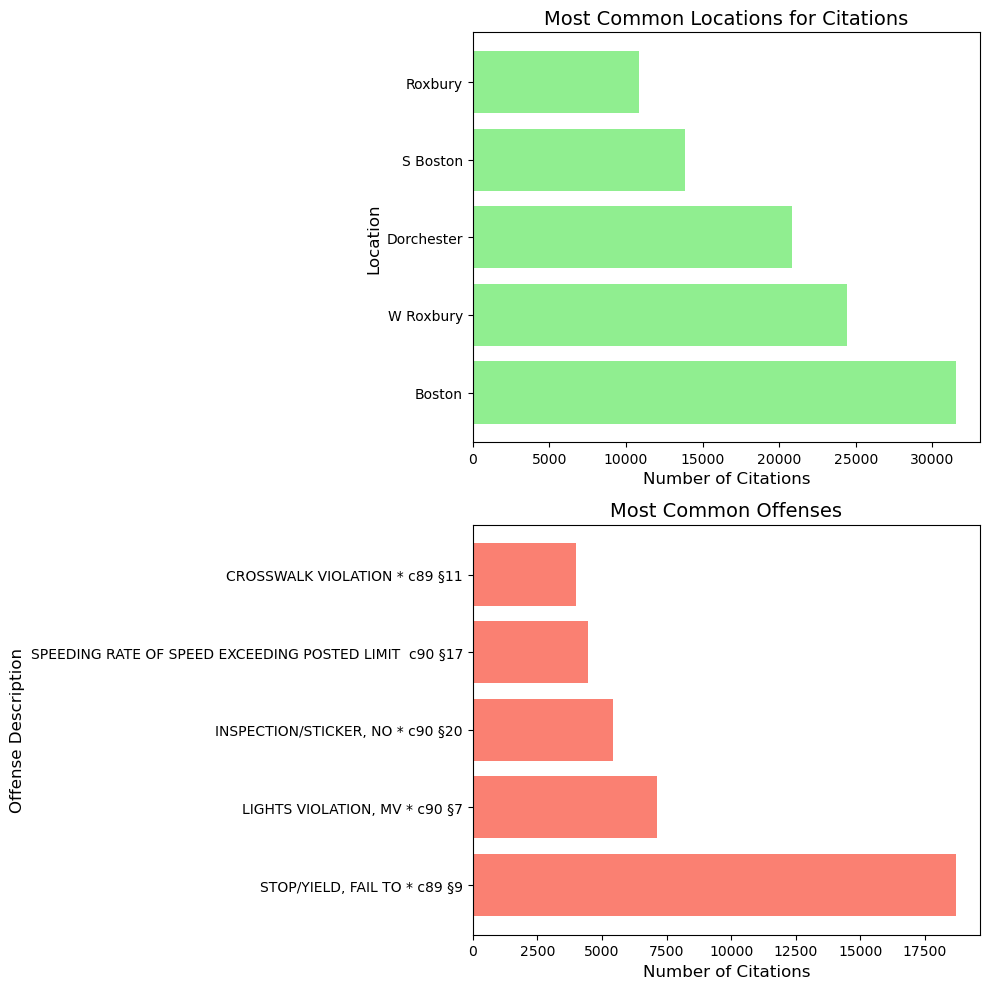

In [4]:
import matplotlib.pyplot as plt

# Set up the figure for subplots
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

# Plot 2: Most common locations
axes[0].barh(most_common_locations.index, most_common_locations.values, color='lightgreen')
axes[0].set_title('Most Common Locations for Citations', fontsize=14)
axes[0].set_xlabel('Number of Citations', fontsize=12)
axes[0].set_ylabel('Location', fontsize=12)

# Plot 3: Most common offenses
axes[1].barh(most_common_offenses.index, most_common_offenses.values, color='salmon')
axes[1].set_title('Most Common Offenses', fontsize=14)
axes[1].set_xlabel('Number of Citations', fontsize=12)
axes[1].set_ylabel('Offense Description', fontsize=12)

# Adjust layout
plt.tight_layout()
plt.show()


In [ ]:
# Plot foor the number of citations per hour of the day

# import pandas as pd
# import matplotlib.pyplot as plt

# # Ensure 'Military Time' is in the correct format
# massdot['Military Time'] = pd.to_datetime(massdot['Military Time'], format='%H:%M', errors='coerce').dt.hour

# # Drop rows with NaT values in 'Military Time'
# massdot = massdot.dropna(subset=['Military Time'])

# # Group by hour and calculate the number of citations
# citations_per_hour = massdot.groupby('Military Time').size()

# # Plot the number of citations per hour
# plt.figure(figsize=(15, 5))
# citations_per_hour.plot(kind='bar', color='skyblue')
# plt.title('Number of Citations per Hour', fontsize=16)
# plt.xlabel('Hour of Day (Military Time)', fontsize=14)
# plt.ylabel('Number of Citations', fontsize=14)
# plt.xticks(rotation=0)
# plt.grid(axis='y', alpha=0.75)
# plt.show()

In [5]:
# Print the head of massdot
massdot.head()

,Agency Code,Issuing Agency,Officer Id,Citation #,Type,Event/Written Date,Time-HH,Time-MM,AM-PM,Location Name,Offense,Offense Description,Race,Gender
0,PD_BPH,Boston Police District C-11,131215,608180AA,WARN,2020-01-01,7.0,10.0,AM,Boston,8980,"YIELD AT INTERSECTION, FAIL * c89 §8",ASIAN,MALE
1,CP_BPX,Boston Police Special OPS,11735,R8170781,CIVIL,2020-01-01,12.0,45.0,AM,Boston,894A0,MARKED LANES VIOLATION * c89 §4A,MIDEST,MALE
2,CP_BPX,Boston Police Special OPS,11735,R8170782,CIVIL,2020-01-01,1.0,25.0,AM,Jamaica Plain,8940,"KEEP RIGHT ON HILL/OBSTRUCTED VIEW, FL * c89 §4",BLACK,MALE
3,CP_BPX,Boston Police Special OPS,NaN,T0987036,CRIM,2020-01-01,NaN,NaN,NaN,Brighton,9010A2,UNLICENSED OPERATION OF MV c90 §10,UNKNWN,MALE
4,PD_BPG,Boston Police District A-7,NaN,T1186933,CRIM,2020-01-01,NaN,NaN,NaN,E Boston,9010A2,UNLICENSED OPERATION OF MV c90 §10,UNKNWN,MALE


In [6]:
# Print the head of records
records.head()

,IDNO6,NAME,RANK,ASSIGNED_DESC,CHARGED_DESC,OTDATE,STARTTIME,ENDTIME,WRKDHRS,OTHOURS
0,8645.0,"Gillespie,Joseph G.",Capt,DISTRICT 18,DISTRICT 18,1/1/20,1200,1600,4.0,4.0
1,10738.0,"Sexton,Richard",Capt,CRIMINAL INVESTIGATIVE DIV.,CRIMINAL INVESTIGATIVE DIV.,1/1/20,1600,1800,2.0,2.0
2,11554.0,"Barcelou,Brian R",Civili,INFORMATION SYSTEMS GROUP,INFORMATION SYSTEMS GROUP,1/1/20,1330,1430,1.0,1.0
3,9843.0,"Bynoe,Sonya D",Civili,OPERATIONS DIVISION,OPERATIONS DIVISION,1/1/20,1600,0,8.0,8.0
4,113177.0,"Cardona,Veronica",Civili,OPERATIONS DIVISION,OPERATIONS DIVISION,1/1/20,0,400,4.0,4.0


In [7]:
# Print the column types of masdot
massdot.dtypes

Agency Code             object
Issuing Agency          object
Officer Id              object
Citation #              object
Type                    object
Event/Written Date      object
Time-HH                float64
Time-MM                float64
AM-PM                   object
Location Name           object
Offense                 object
Offense Description     object
Race                    object
Gender                  object
dtype: object

In [16]:
# Convert the "STARTTIME" column in records to military time like 00:00
records['STARTTIME'] = records['STARTTIME'].astype(str)
records['Military Start Time'] = records['STARTTIME'].apply(lambda x: '00:00' if x == '0' else f"{x.zfill(4)[:2]}:{x.zfill(4)[2:]}")

# Convert the "ENDTIME" column in records to military time like 00:00
records['ENDTIME'] = records['ENDTIME'].astype(str)
records['Military End Time'] = records['ENDTIME'].apply(lambda x: '00:00' if x == '0' else f"{x.zfill(4)[:2]}:{x.zfill(4)[2:]}")

In [18]:
# Change "IDNO6" from a float64 to an object 8645.0 to 8645 using strip
records['IDNO6'] = records['IDNO6'].astype(str)
records['IDNO6'] = records['IDNO6'].apply(lambda x: x.strip('.0'))

In [19]:
# Reset the index of both dataframes
massdot = massdot.reset_index(drop=True)
records = records.reset_index(drop=True)

In [20]:
records.head()

,IDNO6,NAME,RANK,ASSIGNED_DESC,CHARGED_DESC,OTDATE,STARTTIME,ENDTIME,WRKDHRS,OTHOURS,Military Start Time,Military End Time
0,8645,"Gillespie,Joseph G.",Capt,DISTRICT 18,DISTRICT 18,1/1/20,1200,1600,4.0,4.0,12:00,16:00
1,10738,"Sexton,Richard",Capt,CRIMINAL INVESTIGATIVE DIV.,CRIMINAL INVESTIGATIVE DIV.,1/1/20,1600,1800,2.0,2.0,16:00,18:00
2,11554,"Barcelou,Brian R",Civili,INFORMATION SYSTEMS GROUP,INFORMATION SYSTEMS GROUP,1/1/20,1330,1430,1.0,1.0,13:30,14:30
3,9843,"Bynoe,Sonya D",Civili,OPERATIONS DIVISION,OPERATIONS DIVISION,1/1/20,1600,0,8.0,8.0,16:00,00:00
4,113177,"Cardona,Veronica",Civili,OPERATIONS DIVISION,OPERATIONS DIVISION,1/1/20,0,400,4.0,4.0,00:00,04:00


In [21]:
massdot['Event/Written Date'] = pd.to_datetime(massdot['Event/Written Date'])
records['OTDATE'] = pd.to_datetime(records['OTDATE'], format='%m/%d/%y')

print(records['OTDATE'][0])
print(massdot['Event/Written Date'][0])
print(records['Military Start Time'][0])
print(massdot['Military Time'][0])
print(records['Military End Time'][0])

records['OTDATE'][0] == massdot['Event/Written Date'][0]

2020-01-01 00:00:00
2020-01-01 00:00:00
12:00
07:10
16:00


True

In [25]:
import pandas as pd

# Initialize an empty list to store matching observations
matching_rows = []

# Loop through the records and massdot dataframes
j_start = 0  # Initialize the starting index for massdot

for i in range(len(records)//1000):
    for j in range(j_start, len(massdot)):
        # Check if the date in records is after the date in massdot
        if records['OTDATE'][i] > massdot['Event/Written Date'][j]:
            j_start = j  # Save the current index to start from here in the next iteration
            break  # Break the inner loop to move to the next record if the date condition fails
        
        # Check if the dates match
        if records['OTDATE'][i] == massdot['Event/Written Date'][j]:
            # Check if the officer IDs match
            if records['IDNO6'][i] == massdot['Officer Id'][j]:
                # Check if the Military Time in massdot falls within the range specified in records
                if records['Military Start Time'][i] <= massdot['Military Time'][j] <= records['Military End Time'][i]:
                    # Add the matching observation to the list as a dictionary
                    matching_rows.append({
                        'Officer Id': massdot['Officer Id'][j],
                        'OTDATE': records['OTDATE'][i],
                        'Event/Written Date': massdot['Event/Written Date'][j],
                        'Military Start Time': records['Military Start Time'][i],
                        'Military Time': massdot['Military Time'][j],
                        'Military End Time': records['Military End Time'][i]
                    })

# Convert the list of matching rows to a DataFrame
quantum = pd.DataFrame(matching_rows, columns=['Officer Id', 'OTDATE', 'Event/Written Date', 'Military Start Time', 'Military Time', 'Military End Time'])


In [27]:
quantum

,Officer Id,OTDATE,Event/Written Date,Military Start Time,Military Time,Military End Time
0,56354,2020-01-01,2020-01-01,16:00,16:15,23:45
1,56354,2020-01-01,2020-01-01,16:00,18:07,23:45
2,56354,2020-01-01,2020-01-01,16:00,18:57,23:45
3,56354,2020-01-01,2020-01-01,16:00,19:04,23:45
4,56354,2020-01-01,2020-01-01,16:00,16:24,23:45
5,56354,2020-01-01,2020-01-01,16:00,18:46,23:45
6,11103,2020-01-01,2020-01-01,07:30,10:35,16:00


In [154]:
# Testing components of the algorithm

print(massdot['Officer Id'][37])
print(records['IDNO6'][110])

print(records['Military Start Time'][110])
print(massdot['Military Time'][37])
print(records['Military End Time'][110])

i = 110
j = 37

if records['OTDATE'][i] == massdot['Event/Written Date'][j]:
    print("True")

if records['IDNO6'][i] == massdot['Officer Id'][j]:
    print("True")

if records['Military Start Time'][i] <= massdot['Military Time'][j] <= records['Military End Time'][i]:
    print("True")

56354
56354
16:00
16:15
23:45
True
True
True


In [ ]:
import pandas as pd

# Step 1: Filter the `massdot` DataFrame if you want to skip rows before `j_start`
massdot_filtered = massdot.iloc[j_start:]

# Step 2: Perform an inner merge to match by date and Officer Id
merged_df = pd.merge(
    massdot_filtered,
    records,
    left_on=['Event/Written Date', 'Officer Id'],
    right_on=['OTDATE', 'IDNO6'],
    suffixes=('_massdot', '_detail')
)

# Step 3: Filter rows where Military Time in massdot is within the range specified in court
quantum = merged_df[
    (merged_df['Military Start Time'] <= merged_df['Military Time']) &
    (merged_df['Military Time'] <= merged_df['Military End Time'])
][[
    'Officer Id', 'OTDATE', 'Event/Written Date', 
    'Military Start Time', 'Military Time', 'Military End Time'
]]

# Reset the index for clean output
quantum = quantum.reset_index(drop=True)


In [34]:
quantum

,Officer Id,OTDATE,Event/Written Date,Military Start Time,Military Time,Military End Time
0,56354,2020-01-01,2020-01-01,16:00,16:15,23:45
1,56354,2020-01-01,2020-01-01,16:00,18:07,23:45
2,56354,2020-01-01,2020-01-01,16:00,18:57,23:45
3,56354,2020-01-01,2020-01-01,16:00,19:04,23:45
4,56354,2020-01-01,2020-01-01,16:00,16:24,23:45
...,...,...,...,...,...,...
6934,144446,2021-12-30,2021-12-30,07:30,12:35,16:00
6935,106745,2021-12-30,2021-12-30,07:30,08:41,16:00
6936,126547,2021-12-30,2021-12-30,16:00,17:26,23:45
6937,126547,2021-12-30,2021-12-30,16:00,17:26,23:45
